In [1]:
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.patches as mpatches

from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from scipy.stats import gamma, beta

from configs.load_config import dict_to_namespace
from data_processing.load import (
    load_dataset,
    load_weather_forecast_parquet,
    load_weather_nowcast,
    load_windparks,
    load_windpower,
)

Overview about bidding zones:

- all operational date
- number of windparks in zone
- theoretical max capacity


In [2]:
windparks = load_windparks("../data/windparks_bidzone.csv")
# Wind park level
substation_summary = windparks.groupby(
    ["bidding_area", "substation_name"], as_index=False
).agg(
    prod_start_new=("prod_start_new", "max"),
    operating_power_max=("operating_power_max", "mean"),
    n_units=("substation_name", "size"),
)
# 2) Bidding zone level
summary = (
    substation_summary.groupby("bidding_area")
    .agg(
        prod_start_all_operational=("prod_start_new", "max"),
        n_windparks=("substation_name", "count"),  # jetzt eindeutig!
        max_capa=("operating_power_max", "sum"),
    )
    .sort_index()
)

summary

,prod_start_all_operational,n_windparks,max_capa
bidding_area,,,
ELSPOT NO1,2022-10-26 22:00:00,6,405.7
ELSPOT NO2,2024-09-09 23:00:00,20,1451.3
ELSPOT NO3,2022-10-12 12:00:00,25,2120.4
ELSPOT NO4,2022-11-29 15:00:00,14,1160.0


Missing weather data for wind parks: four in total

- two in NO2
- one in NO3
- one in NO4

(renaming of two in nowcast)


In [3]:
data_path = "../data"
weather_forecast = load_weather_forecast_parquet(f"{data_path}/met_forecast.parquet")
weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")
windpower = load_windpower(f"{data_path}/wind_power_per_bidzone.parquet")
windparks = load_windparks(f"{data_path}/windparks_bidzone.csv")
meta_parks = pd.Index(windparks["substation_name"].dropna().unique())

forecast_parks = pd.Index(weather_forecast["sid"].dropna().unique())
nowcast_parks = pd.Index(weather_nowcast["windpark"].dropna().unique())

missing_in_forecast = meta_parks.difference(forecast_parks)
missing_in_nowcast = meta_parks.difference(nowcast_parks)

missing_in_parks_f = forecast_parks.difference(meta_parks)
missing_in_parks_n = nowcast_parks.difference(meta_parks)

print(f"forecast: {missing_in_forecast, missing_in_parks_f}")
print(f"nowcast: {missing_in_nowcast, missing_in_parks_n}")

forecast: (Index(['Hinnøy', 'Håvik', 'Orkdal', 'Ramslandsvågen'], dtype='object'), Index([], dtype='object'))
nowcast: (Index(['Hinnøy', 'Håvik', 'Orkdal', 'Ramslandsvågen'], dtype='object'), Index([], dtype='object'))


Datasets start and end dates

- nowcast: '2020-01-01 01:00:00+0100' to '2025-04-01 01:00:00+0200'
- forecast: '2020-02-17 00:00:00+0100' to '2025-03-26 23:00:00+0100'
- windpower: '2020-01-01 01:00:00+0100' to '2025-04-03 10:00:00+0200'


In [4]:
windpower = load_windpower(f"{data_path}/wind_power_per_bidzone.parquet")
windpower.index.min(), windpower.index.max()

(Timestamp('2020-01-01 01:00:00+0100', tz='CET'),
 Timestamp('2025-04-03 10:00:00+0200', tz='CET'))

In [5]:
data_path = "../data"
weather_forecast = load_weather_forecast_parquet(f"{data_path}/met_forecast.parquet")
weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")


# Keep only two day ahead entries
forecast_day = weather_forecast["time"].dt.floor("D")
ref_day_plus_2 = weather_forecast["time_ref"].dt.floor("D") + pd.Timedelta(days=2)
weather_forecast_filtered = weather_forecast.loc[forecast_day == ref_day_plus_2].copy()
print(f"After 2-day ahead filtering: {len(weather_forecast_filtered)} rows")
print(
    f"Lead time range: {weather_forecast_filtered['lt'].min():.1f}h "
    f"to {weather_forecast_filtered['lt'].max():.1f}h"
)

forecast_times = pd.Index(weather_forecast_filtered["time"].unique())
nowcast_times = weather_nowcast.index

non_overlapping_f = forecast_times.difference(nowcast_times)
non_overlapping_n = nowcast_times.difference(forecast_times)

print(non_overlapping_f, "\n", non_overlapping_n)

After 2-day ahead filtering: 2592073 rows
Lead time range: 34.0h to 61.0h
DatetimeIndex(['2024-08-21 00:00:00+02:00'], dtype='datetime64[ns, CET]', freq=None) 
 DatetimeIndex(['2020-01-01 01:00:00+01:00', '2020-01-01 02:00:00+01:00',
               '2020-01-01 03:00:00+01:00', '2020-01-01 04:00:00+01:00',
               '2020-01-01 05:00:00+01:00', '2020-01-01 06:00:00+01:00',
               '2020-01-01 07:00:00+01:00', '2020-01-01 08:00:00+01:00',
               '2020-01-01 09:00:00+01:00', '2020-01-01 10:00:00+01:00',
               ...
               '2025-03-31 16:00:00+02:00', '2025-03-31 17:00:00+02:00',
               '2025-03-31 18:00:00+02:00', '2025-03-31 19:00:00+02:00',
               '2025-03-31 20:00:00+02:00', '2025-03-31 21:00:00+02:00',
               '2025-03-31 22:00:00+02:00', '2025-03-31 23:00:00+02:00',
               '2025-04-01 00:00:00+02:00', '2025-04-01 01:00:00+02:00'],
              dtype='datetime64[ns, CET]', length=3515, freq=None)


Plot ensemble member forecast horizon


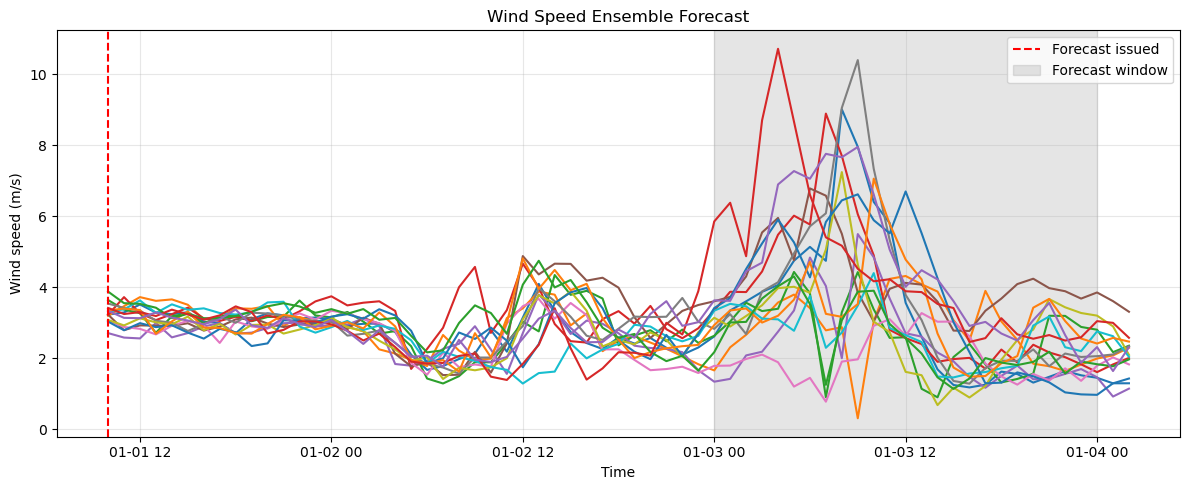

In [6]:
forecast_1dp_filterd = weather_forecast[
    (weather_forecast["time_ref"] == pd.Timestamp("2025-01-01 10:00:00+01:00"))
    & (weather_forecast["sid"] == "Engerfjellet")
]


ensemble_cols = [col for col in weather_forecast.columns if "ws10m" in col]
plt.figure(figsize=(12, 5))
plt.plot(forecast_1dp_filterd["time"], forecast_1dp_filterd[ensemble_cols])

# Initialization
plt.axvline(
    pd.to_datetime("2025-01-01 10:00:00+01:00"),
    color="red",
    linestyle="--",
    label="Forecast issued",
)

# Forecast window
plt.axvspan(
    pd.to_datetime("2025-01-03 00:00:00+01:00"),
    pd.to_datetime("2025-01-04 00:00:00+01:00"),
    color="grey",
    alpha=0.2,
    label="Forecast window",
)


plt.title("Wind Speed Ensemble Forecast")
plt.xlabel("Time")
plt.ylabel("Wind speed (m/s)")
plt.grid(alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../plots/ensemble_forecast_ws.pdf")

Correlation plot wind speed and wind power per bidding zone


In [7]:
wind_speed_zones = []
wind_power_gen_zones = []
scalers = []
for i in range(1, 5):
    data_cfg = dict_to_namespace(
        {
            "dataset": "nowcast",
            "bid_zone": f"ELSPOT NO{i}",
            "split_time": "2025-01-01 00:00:00",
        }
    )
    data = load_dataset(data_cfg)
    idx = data["feature_cols"].index("wind_speed_10m")

    wind_speed = data["X_train"][:, :, idx]
    wind_power_gen = data["Y_train_gen"]
    wind_power_cf = data["Y_train_cf"]

    wind_speed_zones.append(wind_speed)
    wind_power_gen_zones.append(wind_power_gen)
    scalers.append(data["scaler_params"])

Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:706: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00


Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
Loading nowcast data for ELSPOT NO2...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:706: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2023-03-14 09:00:00
Maintenance hours in operational period: 217
Preprocessing done. X_train shape: (15599, 17, 10)
Preprocessing done. X_test shape: (2149, 17, 10)
Loading nowcast data for ELSPOT NO3...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:706: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-12 12:00:00
Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (19025, 24, 10)
Preprocessing done. X_test shape: (2160, 24, 10)
Loading nowcast data for ELSPOT NO4...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:706: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-11-29 15:00:00
Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (17771, 13, 10)
Preprocessing done. X_test shape: (2160, 13, 10)


Spearman:

- non-parametric measure of monotonic relationship between two variables
- ranging from -1 to +1
- assesses how well relationship between variables can be described by a monotonic function (rather than assuming a linear relationship like Pearson's correlation)


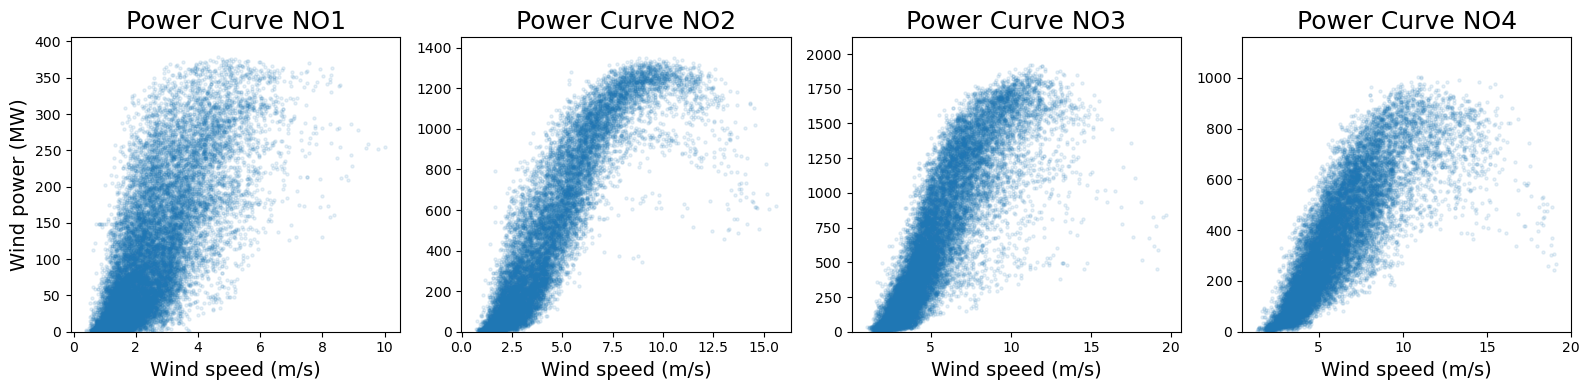

In [8]:
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(4 * 4, 4))

max_cap = [405.7, 1451.3, 2120.4, 1160.0]
for i, ax in enumerate(axes):
    _, S = wind_speed_zones[i].shape
    s = wind_speed_zones[i].mean(axis=-1)
    scaler = scalers[i]

    p = wind_power_gen_zones[i]
    scaler = scalers[i]
    s_unscaled = s * scaler["std"]["wind_speed_10m"] + scaler["mean"]["wind_speed_10m"]

    ax.scatter(
        s_unscaled,
        p,
        s=5,
        alpha=0.1,
    )
    ax.set_title(f"Power Curve NO{i+1}", fontsize=18)
    ax.set_xlabel("Wind speed (m/s)", fontsize=14)
    ax.set_ylim(0, max_cap[i])


axes[0].set_ylabel("Wind power (MW)", fontsize=14)
plt.tight_layout()

plt.savefig("../plots/windpowercurves.pdf", bbox_inches="tight")

CRPS Visualization


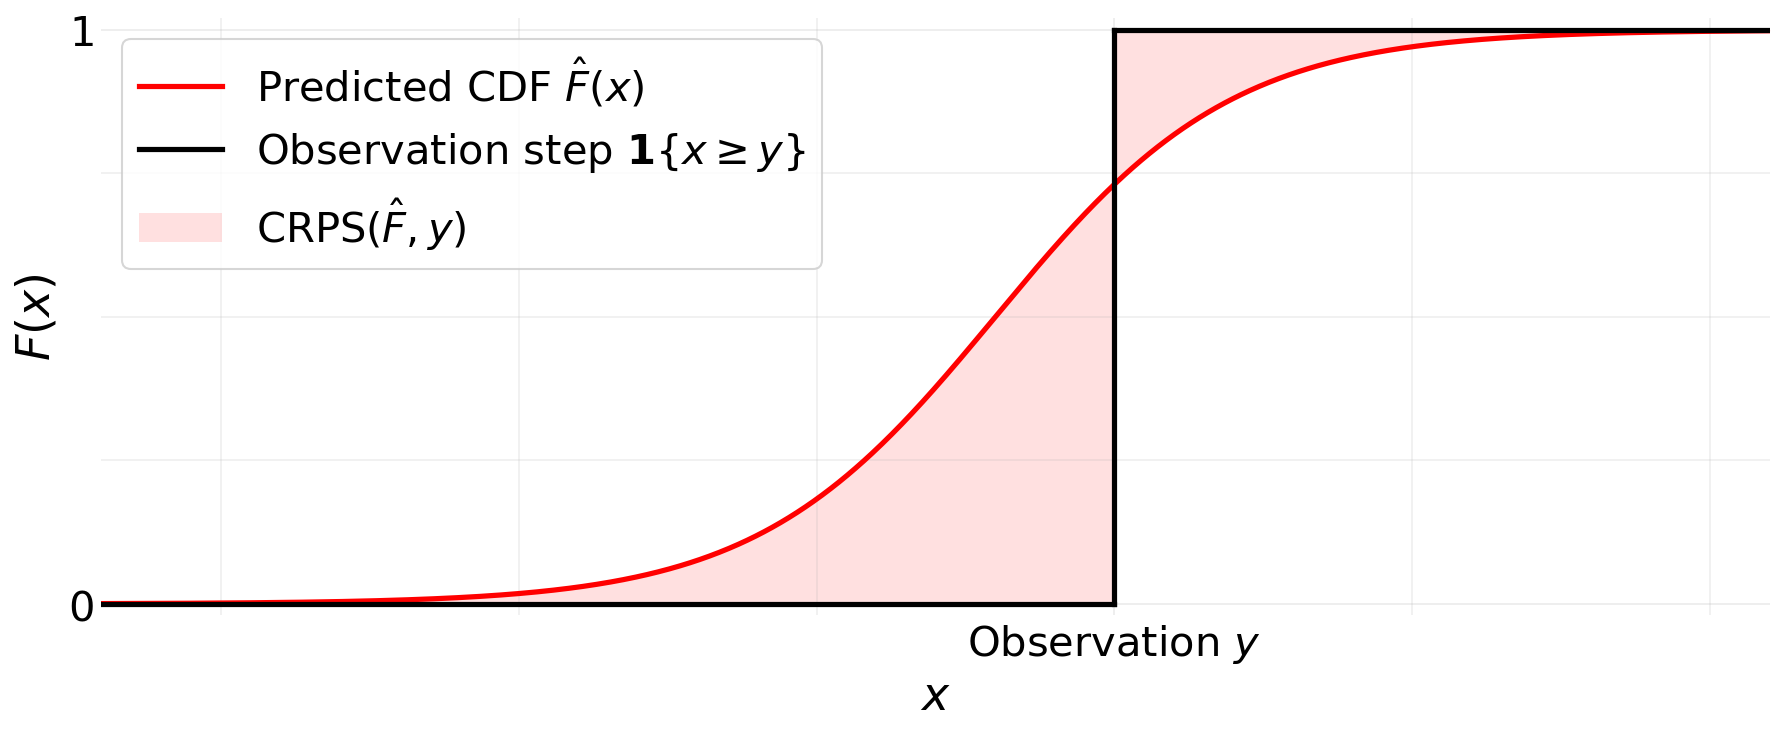

In [9]:
# Setup
y = 0.5  # observed value
x = np.linspace(-1.2, +1.6, 1200)

# Predicted CDF F(x): logistic CDF
s = 0.2
F = 1 / (1 + np.exp(-(x - 0.3) / s))

# Plot
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)

# Predicted CDF
ax.plot(x, F, color="red", lw=2.5, label=r"Predicted CDF $\hat{F}(x)$")

# Observation step function 1{x > y}
ax.plot([x.min(), y], [0, 0], color="black", lw=2.5)
ax.plot([y, y], [0, 1], color="black", lw=2.5)
ax.plot(
    [y, x.max()],
    [1, 1],
    color="black",
    lw=2.5,
    label=r"Observation step $\mathbf{1}\{x \geq y\}$",
)

# Shaded CRPS area
mask_left = x <= y
ax.fill_between(x[mask_left], 0, F[mask_left], color="red", alpha=0.12, linewidth=0)

mask_right = x >= y
ax.fill_between(
    x[mask_right],
    F[mask_right],
    1,
    color="red",
    alpha=0.12,
    linewidth=0,
    label=r"CRPS$(\hat{F},y)$",
)

ax.set_xlim(x.min(), x.max())
ax.set_ylim(-0.02, 1.02)

ax.set_xlabel(r"$x$", fontsize=22)
ax.set_ylabel(r"$F(x)$", fontsize=22)

# Tick placement
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
ax.yaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.25))

# Only label observation y on x-axis
ax.set_xticks([y])
ax.set_xticklabels([r"Observation $y$"], fontsize=20)
ax.set_yticks([0, 1])
ax.set_yticklabels([r"$0$", r"$1$"], fontsize=20)

# Grid
ax.grid(True, which="major", alpha=0.25)
ax.grid(True, which="minor", alpha=0.2)

# Hide tick marks
ax.tick_params(which="major", length=0)
ax.tick_params(which="minor", length=0, width=0)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(fontsize=20, loc="upper left")

plt.tight_layout()
plt.savefig("../plots/crps.pdf", bbox_inches="tight")
plt.show()

Visualize Gamma and Beta distributions


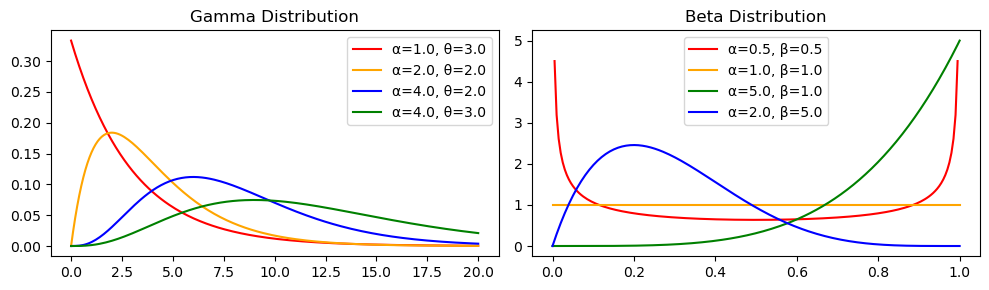

In [10]:
# Create figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

# -------------------
# Gamma distribution
# -------------------
x_gamma = np.linspace(1e-4, 20, 200)

gamma_curves = [
    (1, 3.0, "red", "α=1.0, θ=3.0"),
    (2.0, 2.0, "orange", "α=2.0, θ=2.0"),
    (4.0, 2.0, "blue", "α=4.0, θ=2.0"),
    (4.0, 3.0, "green", "α=4.0, θ=3.0"),
]

for k, theta, color, label in gamma_curves:
    y = gamma.pdf(x_gamma, a=k, scale=theta)
    axes[0].plot(x_gamma, y, color=color, label=label)

axes[0].set_title("Gamma Distribution")
axes[0].legend()
# axes[0].grid()


# -------------------
# Beta distribution
# -------------------
x_beta = np.linspace(0, 1, 200)

beta_curves = [
    (0.5, 0.5, "red", "α=0.5, β=0.5"),
    (1, 1, "orange", "α=1.0, β=1.0"),
    (5.0, 1.0, "green", "α=5.0, β=1.0"),
    (2.0, 5.0, "blue", "α=2.0, β=5.0"),
]

for a, b, color, label in beta_curves:
    y = beta.pdf(x_beta, a=a, b=b)
    axes[1].plot(x_beta, y, color=color, label=label)

axes[1].set_title("Beta Distribution")
axes[1].legend()
# axes[1].grid()


plt.tight_layout()
plt.savefig("../plots/distributions.pdf")

correlation_average_weather
correlation_wind_speed_10m


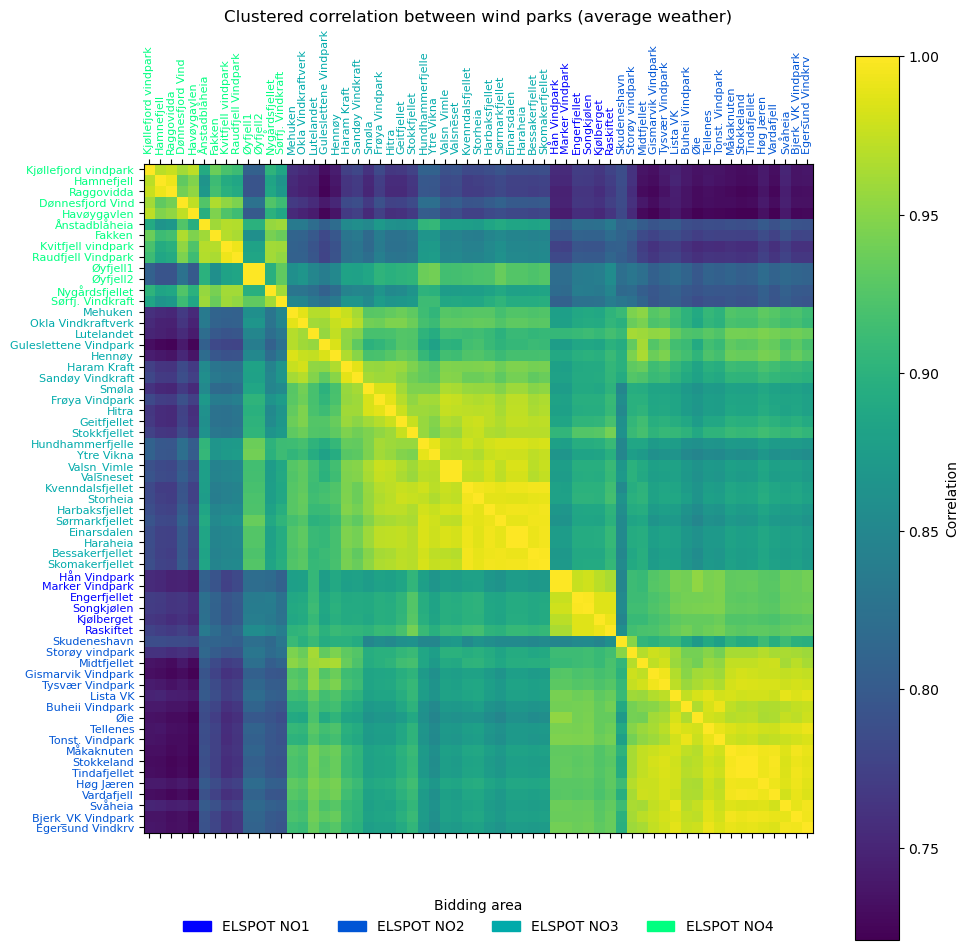

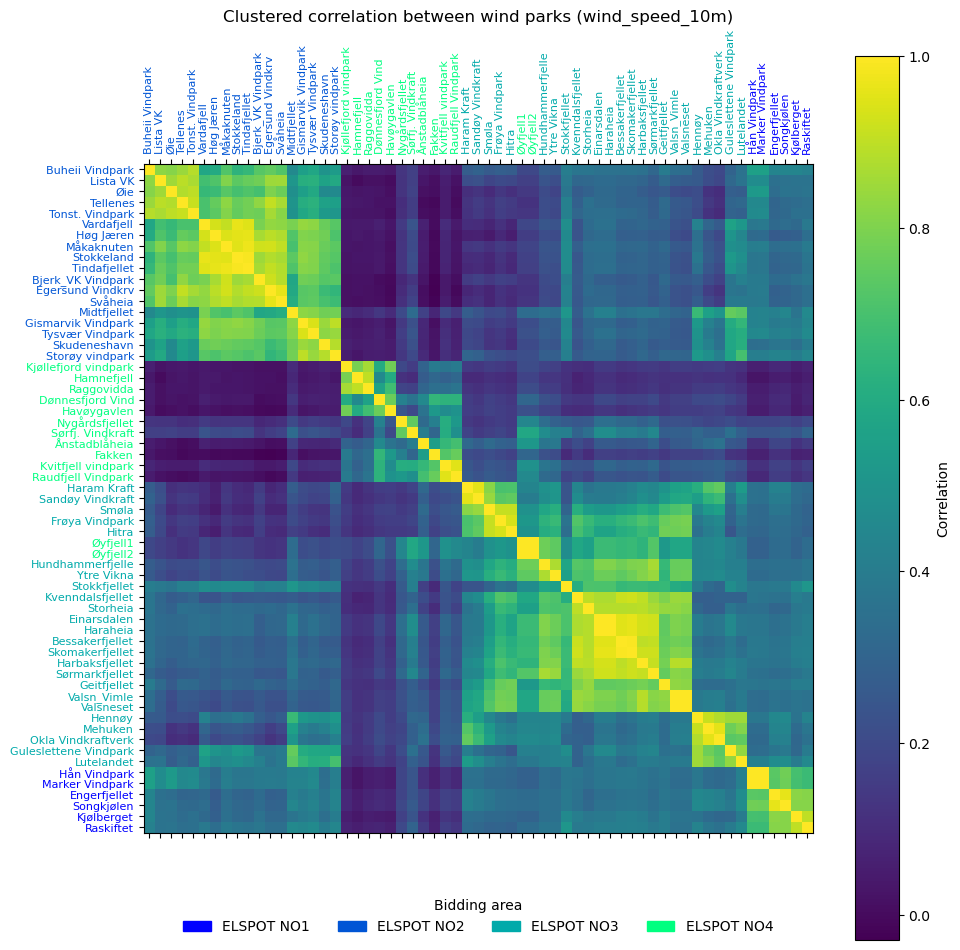

In [11]:
def correlation_across_zones(features):
    weather_nowcast = load_weather_nowcast(f"{data_path}/met_nowcast.parquet")
    windparks = load_windparks(f"{data_path}/windparks_bidzone.csv")
    windparks_unique = (
        windparks[["bidding_area", "substation_name"]]
        .drop_duplicates()
        .set_index("substation_name")
    )
    merged = weather_nowcast.join(windparks_unique[["bidding_area"]], on="windpark")
    n_parks = len(list(set(merged["windpark"].values)))

    Ds = []

    for feature in features:
        dfs = dict(tuple(merged[[feature, "windpark"]].groupby("windpark")))
        df = pd.DataFrame()

        for key in dfs.keys():
            df[key] = dfs[key][feature]

        x = df.to_numpy()

        # Angular similarity
        if feature == "wind_direction_10m":
            # Convert degrees to radians
            theta = np.deg2rad(df.to_numpy(dtype=float))  # shape (T, N)

            # Similarity matrix S_ij = mean(cos(theta_i - theta_j))
            C = np.zeros((n_parks, n_parks), dtype=float)

            for i in range(n_parks):
                ti = theta[:, i]
                for j in range(n_parks):
                    tj = theta[:, j]

                    diff = ti - tj
                    sim = float(np.mean(np.cos(diff)))

                    C[i, j] = sim
                    C[j, i] = sim

        # Pearson correlation coeffient
        else:
            C = np.corrcoef(x.T)

        # Distance
        Ds.append(1 - C)

    # weighted aggregation of different weather distances
    weights = [1 for _ in range(len(Ds))]
    D = sum(w * D for w, D in zip(weights, Ds))

    # Condensed form
    dist = squareform(D, checks=False)

    # Clustering
    Z = linkage(dist, method="ward")

    # Sort matrix and labels
    order = leaves_list(Z)
    C_sorted = C[np.ix_(order, order)]
    labels = df.columns.to_numpy()[order]

    zones = windparks_unique["bidding_area"].unique()
    cmap = plt.get_cmap("winter")
    colors = {z: cmap(i / (len(zones) - 1)) for i, z in enumerate(zones)}
    plt.figure(figsize=(10, 10))
    plt.matshow(C_sorted, fignum=0)
    plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
    plt.yticks(range(len(labels)), labels, fontsize=8)
    plt.colorbar(label="Correlation")
    ax = plt.gca()

    # X-Labels färben
    for label, tick_x, tick_y in zip(
        labels, ax.get_xticklabels(), ax.get_yticklabels()
    ):
        tick_x.set_color(colors[windparks_unique.loc[label, "bidding_area"]])
        tick_y.set_color(colors[windparks_unique.loc[label, "bidding_area"]])

    # Create legend handles
    handles = [mpatches.Patch(color=colors[z], label=z) for z in zones]

    # Add legend below plot
    ax.legend(
        handles=handles,
        title="Bidding area",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),  # below figure
        ncol=len(zones),  # one row
        frameon=False,
    )

    plt.tight_layout()
    feature = "average weather" if len(features) > 2 else features[0]
    plt.title(f"Clustered correlation between wind parks ({feature})")
    file_name = "correlation_" + feature.replace(" ", "_")
    print(file_name)
    plt.savefig("../plots/" + file_name + ".pdf", bbox_inches="tight")


data_path = "../data/"
correlation_across_zones(
    [
        "wind_direction_10m",
        "wind_speed_10m",
        "air_pressure_at_sea_level",
        "relative_humidity_2m",
        "air_temperature_2m",
    ]
)
correlation_across_zones(["wind_speed_10m"])

Plot commisioning dates


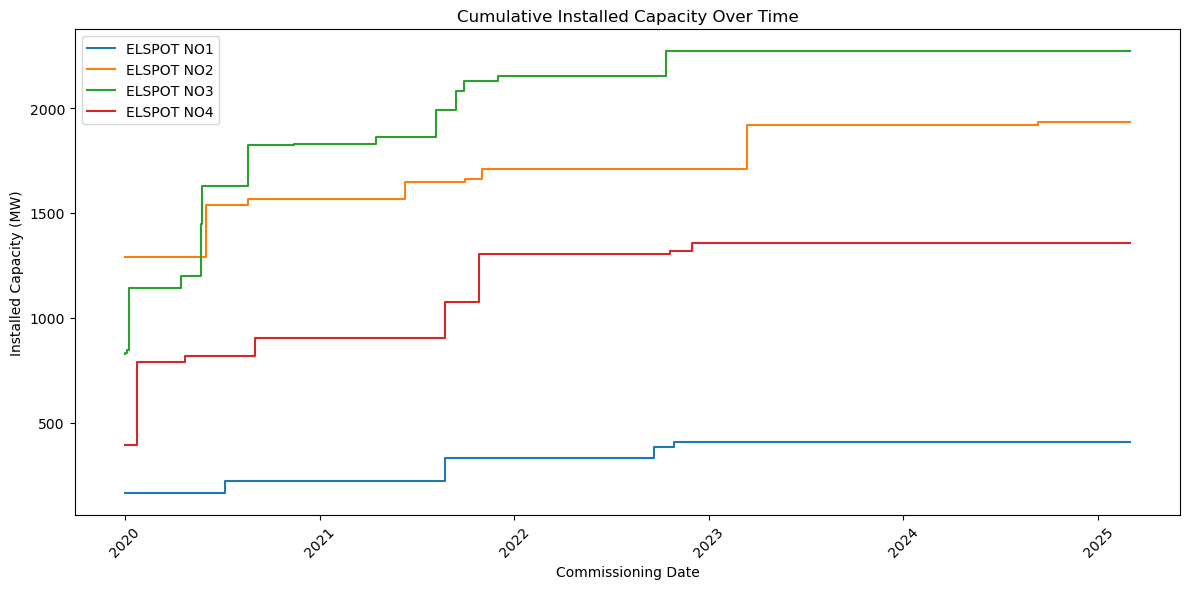

In [12]:
windparks["prod_start_new"] = pd.to_datetime(windparks["prod_start_new"])
end_date = pd.Timestamp("2025-03-01 00:00:00")

plt.figure(figsize=(12, 6))

for bz, df in windparks.groupby("bidding_area"):
    # Sum capacity per commissioning timestamp (prevents stacked vertical lines)
    s = df.groupby("prod_start_new")["operating_power_max"].sum().sort_index()

    # Cumulative capacity
    cum = s.cumsum()

    # Extend flat to end_date
    if end_date > cum.index.max():
        cum.loc[end_date] = cum.iloc[-1]
        cum = cum.sort_index()

    plt.step(cum.index, cum.values, where="post", label=bz)

plt.xlabel("Commissioning Date")
plt.ylabel("Installed Capacity (MW)")
plt.title("Cumulative Installed Capacity Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.savefig("../plots/installed_capacities.pdf", bbox_inches="tight")